# 供应链运输时效与成本分析

用 pandas 分析 10,324 条供应链运输记录，回答三个问题：

1. 哪种运输方式的订单量、平均延误和迟到率更差？
2. 延误集中在哪些国家、供应商、月份？
3. 运费与重量是什么关系？是否存在异常订单？

数据来源：Kaggle Supply Chain Shipment Pricing Data（约 2006–2015 年）。详细结论见 [README](README.md)。

## 1. 导入库

导入 pandas 和 matplotlib，并设置中文字体，避免图表中文显示为方框。

In [1]:
# 导入分析所需的库，并设置 matplotlib 中文字体
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["font.sans-serif"] = ["SimHei"]
plt.rcParams["axes.unicode_minus"] = False

## 2. 读取数据

读取 `data/Raw_Data.csv`，确认文件路径和数据结构。

In [2]:
# 读取原始数据，并确认文件路径
from pathlib import Path

print("当前目录:", Path.cwd())
p = Path("data/Raw_Data.csv")
print("解析后:", p.resolve())
print("文件存在:", p.exists())

当前目录: C:\Users\20435\Desktop\logistics-portfolio\project-1-supply-chain
解析后: C:\Users\20435\Desktop\logistics-portfolio\project-1-supply-chain\data\Raw_Data.csv
文件存在: True


In [3]:
df=pd.read_csv("data/Raw_Data.csv")
display(df)

,Ã¯Â»Â¿ID,Project Code,PQ #,PO / SO #,ASN/DN #,Country,Managed By,Fulfill Via,Vendor INCO Term,Shipment Mode,...,Line Item Value,Pack Price,Unit Price,Manufacturing Site,First Line Designation,Weight (Kilograms),Freight Cost (USD),Line Item Insurance (USD),Load_Date,Source_System
0,1,100-CI-T01,Pre-PQ Process,SCMS-4,ASN-8,CÃÂ´te d'Ivoire,PMO - US,Direct Drop,EXW,Air,...,551.00,29.00,0.97,Ranbaxy Fine Chemicals LTD,Yes,13,780.34,NaN,1/17/2026,Kaggle_SCMS
1,3,108-VN-T01,Pre-PQ Process,SCMS-13,ASN-85,Vietnam,PMO - US,Direct Drop,EXW,Air,...,6200.00,6.20,0.03,"Aurobindo Unit III, India",Yes,358,4521.5,NaN,NaN,NaN
2,4,100-CI-T01,Pre-PQ Process,SCMS-20,ASN-14,CÃÂ´te d'Ivoire,PMO - US,Direct Drop,FCA,Air,...,40000.00,80.00,0.80,ABBVIE GmbH & Co.KG Wiesbaden,Yes,171,1653.78,NaN,NaN,NaN
3,15,108-VN-T01,Pre-PQ Process,SCMS-78,ASN-50,Vietnam,PMO - US,Direct Drop,EXW,Air,...,127360.80,3.99,0.07,"Ranbaxy, Paonta Shahib, India",Yes,1855,16007.06,NaN,NaN,NaN
4,16,108-VN-T01,Pre-PQ Process,SCMS-81,ASN-55,Vietnam,PMO - US,Direct Drop,EXW,Air,...,121600.00,3.20,0.05,"Aurobindo Unit III, India",Yes,7590,45450.08,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10319,86818,103-ZW-T30,FPQ-15197,SO-50020,DN-4307,Zimbabwe,PMO - US,From RDC,N/A - From RDC,Truck,...,599655.60,3.60,0.06,"Mylan, H-12 & H-13, India",No,See DN-4307 (ID#:83920),See DN-4307 (ID#:83920),705.79,NaN,NaN
10320,86819,104-CI-T30,FPQ-15259,SO-50102,DN-4313,CÃÂ´te d'Ivoire,PMO - US,From RDC,N/A - From RDC,Truck,...,137389.44,6.52,0.11,Hetero Unit III Hyderabad IN,No,See DN-4313 (ID#:83921),See DN-4313 (ID#:83921),161.71,NaN,NaN
10321,86821,110-ZM-T30,FPQ-14784,SO-49600,DN-4316,Zambia,PMO - US,From RDC,N/A - From RDC,Truck,...,5140114.74,9.99,0.33,Cipla Ltd A-42 MIDC Mahar. IN,No,Weight Captured Separately,Freight Included in Commodity Cost,"5,284.04",NaN,NaN
10322,86822,200-ZW-T30,FPQ-16523,SO-51680,DN-4334,Zimbabwe,PMO - US,From RDC,N/A - From RDC,Truck,...,113871.80,6.52,0.11,Mylan (formerly Matrix) Nashik,Yes,1392,Freight Included in Commodity Cost,134.03,NaN,NaN


## 3. 数据概览

查看前几行、字段类型、非空数量和缺失值分布。

In [4]:
# 查看前 3 行
df.head(3)

,Ã¯Â»Â¿ID,Project Code,PQ #,PO / SO #,ASN/DN #,Country,Managed By,Fulfill Via,Vendor INCO Term,Shipment Mode,...,Line Item Value,Pack Price,Unit Price,Manufacturing Site,First Line Designation,Weight (Kilograms),Freight Cost (USD),Line Item Insurance (USD),Load_Date,Source_System
0,1,100-CI-T01,Pre-PQ Process,SCMS-4,ASN-8,CÃÂ´te d'Ivoire,PMO - US,Direct Drop,EXW,Air,...,551.0,29.0,0.97,Ranbaxy Fine Chemicals LTD,Yes,13,780.34,NaN,1/17/2026,Kaggle_SCMS
1,3,108-VN-T01,Pre-PQ Process,SCMS-13,ASN-85,Vietnam,PMO - US,Direct Drop,EXW,Air,...,6200.0,6.2,0.03,"Aurobindo Unit III, India",Yes,358,4521.5,NaN,NaN,NaN
2,4,100-CI-T01,Pre-PQ Process,SCMS-20,ASN-14,CÃÂ´te d'Ivoire,PMO - US,Direct Drop,FCA,Air,...,40000.0,80.0,0.80,ABBVIE GmbH & Co.KG Wiesbaden,Yes,171,1653.78,NaN,NaN,NaN


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10324 entries, 0 to 10323
Data columns (total 35 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Ã¯Â»Â¿ID                      10324 non-null  int64  
 1   Project Code                  10324 non-null  str    
 2   PQ #                          10324 non-null  str    
 3   PO / SO #                     10324 non-null  str    
 4   ASN/DN #                      10324 non-null  str    
 5   Country                       10324 non-null  str    
 6   Managed By                    10324 non-null  str    
 7   Fulfill Via                   10324 non-null  str    
 8   Vendor INCO Term              10324 non-null  str    
 9   Shipment Mode                 9964 non-null   str    
 10  PQ First Sent to Client Date  10324 non-null  str    
 11  PO Sent to Vendor Date        10324 non-null  str    
 12  Scheduled Delivery Date       10324 non-null  str    
 13  Delivered to

In [6]:
df.isna().sum().sort_values(ascending=False).head(10)

Load_Date                    10323
Source_System                10323
Dosage                        1736
Shipment Mode                  360
Line Item Insurance (USD)      287
Ã¯Â»Â¿ID                         0
Project Code                     0
PQ #                             0
PO / SO #                        0
Country                          0
dtype: int64

## 4. 数据清洗

原始数据存在 5 类问题，需要先处理才能分析：

1. 列名和文本有编码乱码
2. 日期是字符串
3. 重量 / 运费带逗号，是字符串
4. 需要派生“延误天数”“是否迟到”
5. 有不需要的列

### 4.1 修复乱码

原始文本被多重编码，先修复列名和文本列，恢复 `ID`、`Côte d'Ivoire` 等正常写法。

In [7]:
def fix_mojibake(s, max_rounds=8):
    """反复修复被多重编码的文本，直到不再变化。"""
    if not isinstance(s, str):
        return s
    for _ in range(max_rounds):
        try:
            new = s.encode("latin-1").decode("utf-8")
        except (UnicodeEncodeError, UnicodeDecodeError):
            break
        if new == s:
            break
        s = new
    return s.lstrip("\ufeff")


df.columns = [fix_mojibake(c) for c in df.columns]
for c in df.columns:
    if pd.api.types.is_string_dtype(df[c]):
        df[c] = df[c].map(fix_mojibake)

df.columns[:5]

Index(['ID', 'Project Code', 'PQ #', 'PO / SO #', 'ASN/DN #'], dtype='str')

### 4.2 日期转换

把三个日期列从字符串转换为 `datetime`，无法解析的值转为 `NaT`。

In [8]:

for c in ["Scheduled Delivery Date", "Delivered to Client Date", "Delivery Recorded Date"]:
    df[c] = pd.to_datetime(df[c], errors="coerce", format="%d-%b-%y")

In [9]:
df[["Scheduled Delivery Date", "Delivered to Client Date"]].dtypes

Scheduled Delivery Date     datetime64[us]
Delivered to Client Date    datetime64[us]
dtype: object

In [10]:
df["Scheduled Delivery Date"].isna().sum()

np.int64(0)

### 4.3 数值转换

去掉千分位逗号后把三列转为数值；备注文字（如 “Weight Captured Separately”）会变成缺失值。

- `Weight (Kilograms)` → 新列 `weight_kg`
- `Freight Cost (USD)` → 新列 `freight_usd`
- `Line Item Insurance (USD)` → 新列 `insurance_usd`

In [11]:
def to_number(s):
    """把带逗号的文本列转成数字，转不了的变 NaN。"""
    s = s.astype(str)                        # ① 全部当文本
    s = s.str.replace(",", "", regex=False)  # ② 去掉逗号
    return pd.to_numeric(s, errors="coerce") # ③ 转数字，失败变 NaN


pairs = [
    ("Weight (Kilograms)", "weight_kg"),
    ("Freight Cost (USD)", "freight_usd"),
    ("Line Item Insurance (USD)", "insurance_usd"),
]

for src, dst in pairs:
    df[dst] = to_number(df[src])

In [12]:
df.head(5)

,ID,Project Code,PQ #,PO / SO #,ASN/DN #,Country,Managed By,Fulfill Via,Vendor INCO Term,Shipment Mode,...,Manufacturing Site,First Line Designation,Weight (Kilograms),Freight Cost (USD),Line Item Insurance (USD),Load_Date,Source_System,weight_kg,freight_usd,insurance_usd
0,1,100-CI-T01,Pre-PQ Process,SCMS-4,ASN-8,Côte d'Ivoire,PMO - US,Direct Drop,EXW,Air,...,Ranbaxy Fine Chemicals LTD,Yes,13,780.34,NaN,1/17/2026,Kaggle_SCMS,13.0,780.34,NaN
1,3,108-VN-T01,Pre-PQ Process,SCMS-13,ASN-85,Vietnam,PMO - US,Direct Drop,EXW,Air,...,"Aurobindo Unit III, India",Yes,358,4521.5,NaN,NaN,NaN,358.0,4521.50,NaN
2,4,100-CI-T01,Pre-PQ Process,SCMS-20,ASN-14,Côte d'Ivoire,PMO - US,Direct Drop,FCA,Air,...,ABBVIE GmbH & Co.KG Wiesbaden,Yes,171,1653.78,NaN,NaN,NaN,171.0,1653.78,NaN
3,15,108-VN-T01,Pre-PQ Process,SCMS-78,ASN-50,Vietnam,PMO - US,Direct Drop,EXW,Air,...,"Ranbaxy, Paonta Shahib, India",Yes,1855,16007.06,NaN,NaN,NaN,1855.0,16007.06,NaN
4,16,108-VN-T01,Pre-PQ Process,SCMS-81,ASN-55,Vietnam,PMO - US,Direct Drop,EXW,Air,...,"Aurobindo Unit III, India",Yes,7590,45450.08,NaN,NaN,NaN,7590.0,45450.08,NaN


In [13]:
df[["weight_kg", "freight_usd", "insurance_usd"]].notna().sum()

weight_kg         6372
freight_usd       6198
insurance_usd    10037
dtype: int64

### 4.4 派生列

生成分析所需的衍生字段，并清理无用列：

1. 计算延误天数
2. 标记是否迟到
3. 计算送达月份
4. 把 `Shipment Mode` 的缺失值填成 `"Unknown"`
5. 删除不需要的列

In [14]:
df[["Delivered to Client Date","Scheduled Delivery Date"]].head(5)

,Delivered to Client Date,Scheduled Delivery Date
0,2006-06-02,2006-06-02
1,2006-11-14,2006-11-14
2,2006-08-27,2006-08-27
3,2006-09-01,2006-09-01
4,2006-08-11,2006-08-11


In [15]:
df[["Delivered to Client Date","Scheduled Delivery Date"]].dtypes

Delivered to Client Date    datetime64[us]
Scheduled Delivery Date     datetime64[us]
dtype: object

In [16]:

df["delivery_delay_days"]=(df["Delivered to Client Date"] - df["Scheduled Delivery Date"]).dt.days

In [17]:
df["delivery_delay_days"].head()

0    0
1    0
2    0
3    0
4    0
Name: delivery_delay_days, dtype: int64

In [18]:
df["is_late"]=df["delivery_delay_days"]>0

In [19]:

df.loc[df["is_late"], ["ID", "Delivered to Client Date", "delivery_delay_days"]].head()

,ID,Delivered to Client Date,delivery_delay_days
24,130,2007-08-21,8
72,772,2009-04-08,29
122,1196,2009-07-10,28
144,1307,2007-03-30,15
202,1926,2008-07-14,4


In [20]:
display(df["is_late"].value_counts())

is_late
False    9138
True     1186
Name: count, dtype: int64

In [21]:

df["delivery_month"] = df["Delivered to Client Date"].dt.to_period("M")

In [22]:
df["delivery_month"]

0        2006-06
1        2006-11
2        2006-08
3        2006-09
4        2006-08
          ...   
10319    2015-07
10320    2015-08
10321    2015-08
10322    2015-08
10323    2015-08
Name: delivery_month, Length: 10324, dtype: period[M]

In [23]:

df["Shipment Mode"] = df["Shipment Mode"].fillna("Unknown")

In [24]:

df = df.drop(columns=["Load_Date", "Source_System"])

### 4.5 清洗后检查

清洗后应为 10,324 行 × 39 列。检查日期范围、延误天数分布和运输方式取值。

In [25]:

df.shape

(10324, 39)

In [26]:
df["Delivered to Client Date"].min()

Timestamp('2006-05-02 00:00:00')

In [27]:
df["Delivered to Client Date"].max()

Timestamp('2015-09-14 00:00:00')

In [28]:
df["delivery_delay_days"].describe()

count    10324.000000
mean        -6.023537
std         27.233640
min       -372.000000
25%         -3.000000
50%          0.000000
75%          0.000000
max        192.000000
Name: delivery_delay_days, dtype: float64

In [29]:
df["Shipment Mode"].value_counts()

Shipment Mode
Air            6113
Truck          2830
Air Charter     650
Ocean           371
Unknown         360
Name: count, dtype: int64

## 5. 问题一：哪种运输方式的延误更严重？

按 `Shipment Mode` 统计订单量、平均延误和迟到率，比较不同运输方式的时效表现。

In [30]:

bb=df.groupby("Shipment Mode").agg(orders=("ID","count"),avg_delay=("delivery_delay_days","mean"),
                                late_rate=("is_late","mean"))
display(bb)

,orders,avg_delay,late_rate
Shipment Mode,,,
Air,6113,-3.763782,0.096025
Air Charter,650,-19.036923,0.115385
Ocean,371,5.870620,0.175202
Truck,2830,-9.921908,0.160777
Unknown,360,-2.511111,0.011111


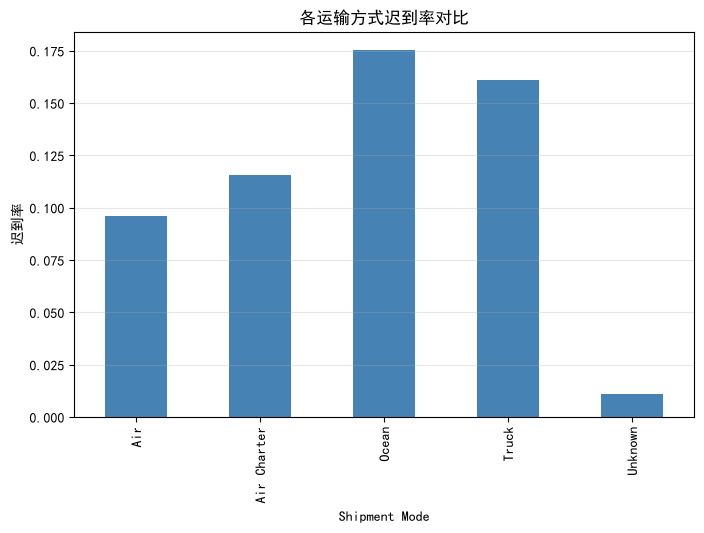

In [31]:
bb["late_rate"].plot.bar(figsize=(8, 5),
    title="各运输方式迟到率对比",
    color="steelblue")
plt.ylabel("迟到率")
plt.grid(axis='y', alpha=0.3)
plt.savefig("charts/late_rate_by_mode.png", dpi=300, bbox_inches="tight")
plt.show()

In [32]:
cc=bb.sort_values(by="avg_delay",ascending=True)
display(cc)

,orders,avg_delay,late_rate
Shipment Mode,,,
Air Charter,650,-19.036923,0.115385
Truck,2830,-9.921908,0.160777
Air,6113,-3.763782,0.096025
Unknown,360,-2.511111,0.011111
Ocean,371,5.870620,0.175202


In [33]:
print("迟到:", (df["delivery_delay_days"] > 0).sum())
print("准时:", (df["delivery_delay_days"] == 0).sum())
print("提前:", (df["delivery_delay_days"] < 0).sum())

迟到: 1186
准时: 6324
提前: 2814


In [34]:
df.nsmallest(5, "delivery_delay_days")[
    ["Scheduled Delivery Date", "Delivered to Client Date", "delivery_delay_days"]
]

,Scheduled Delivery Date,Delivered to Client Date,delivery_delay_days
7738,2013-01-31,2012-01-25,-372
9620,2013-01-31,2012-01-25,-372
430,2008-01-29,2007-01-24,-370
7289,2013-02-28,2012-02-26,-368
76,2009-05-17,2008-10-09,-220


In [35]:
display(df.nlargest(5, "delivery_delay_days")[
    ["Scheduled Delivery Date", "Delivered to Client Date", "delivery_delay_days"]
])

,Scheduled Delivery Date,Delivered to Client Date,delivery_delay_days
2782,2010-08-24,2011-03-04,192
6880,2013-08-27,2014-02-08,165
6881,2013-08-27,2014-02-08,165
7793,2013-08-27,2014-02-08,165
7794,2013-08-27,2014-02-08,165


## 6. 问题二：延误集中在哪些国家、供应商、月份？

从国家、供应商、月份三个维度定位延误集中点；分析供应商时过滤订单量过小的组，避免小样本导致迟到率虚高。

In [36]:
country_stat=df.groupby("Country").agg(country_avg_delay=("delivery_delay_days","mean"),
                                       订单量=("ID", "count"),
                                       country_late_rate=("is_late","mean"))
country_stat=country_stat.loc[country_stat["订单量"]>=50]
top10=country_stat.nlargest(10,"country_late_rate")
top10

,country_avg_delay,订单量,country_late_rate
Country,,,
Burundi,-8.448980,98,0.387755
"Congo, DRC",11.240240,333,0.249249
Mozambique,-1.209192,631,0.183835
Zambia,-5.234261,683,0.158126
Zimbabwe,-11.007435,538,0.143123
Ghana,-0.224138,58,0.137931
South Sudan,-1.067073,164,0.128049
Tanzania,-4.394990,519,0.127168
Kenya,0.891892,111,0.126126


In [37]:
aa=df.groupby("Vendor").agg(迟到率=("is_late","mean"),订单量=("ID","count"),迟到订单数=("is_late", "sum"))
aa=aa.loc[aa["订单量"]>=50]
total_late = aa["迟到订单数"].sum()
aa["迟到占比"] = aa["迟到订单数"]/total_late
topp10=aa.nlargest(10,"迟到率")
topp10

,迟到率,订单量,迟到订单数,迟到占比
Vendor,,,,
SCMS from RDC,0.171540,5404,927,0.788936
Aurobindo Pharma Limited,0.140719,668,94,0.080000
CIPLA LIMITED,0.131429,175,23,0.019574
"Orgenics, Ltd",0.129973,754,98,0.083404
STRIDES ARCOLAB LIMITED,0.043011,93,4,0.003404
"Standard Diagnostics, Inc.",0.040816,98,4,0.003404
"SHANGHAI KEHUA BIOENGINEERING CO.,LTD. (KHB)",0.028571,70,2,0.001702
Orasure Technologies Inc.,0.017857,56,1,0.000851
S. BUYS WHOLESALER,0.015385,715,11,0.009362


In [38]:
# 问题二：按月份分组
# 1. 按月份分组，同时统计3个核心指标（对应：groupby + 命名聚合）
month_trend = df.groupby("delivery_month").agg(
    订单总量=("ID", "count"),
    平均延误天数=("delivery_delay_days", "mean"),
    迟到率=("is_late", "mean")
)

# 2. 数值美化（对应：补充9 round 四舍五入）
month_trend["平均延误天数"] = month_trend["平均延误天数"].round(2)
month_trend["迟到率"] = (month_trend["迟到率"] * 100).round(2)

# 查看月度延误趋势表
month_trend.nlargest(10,"迟到率")

,订单总量,平均延误天数,迟到率
delivery_month,,,
2010-10,54,6.52,53.70
2011-05,74,8.99,50.00
2011-06,107,5.23,37.38
2011-07,91,4.54,37.36
2010-12,102,4.13,37.25
2013-08,98,14.40,36.73
2014-02,178,17.19,34.27
2014-09,135,3.96,31.85
2011-01,51,2.49,27.45


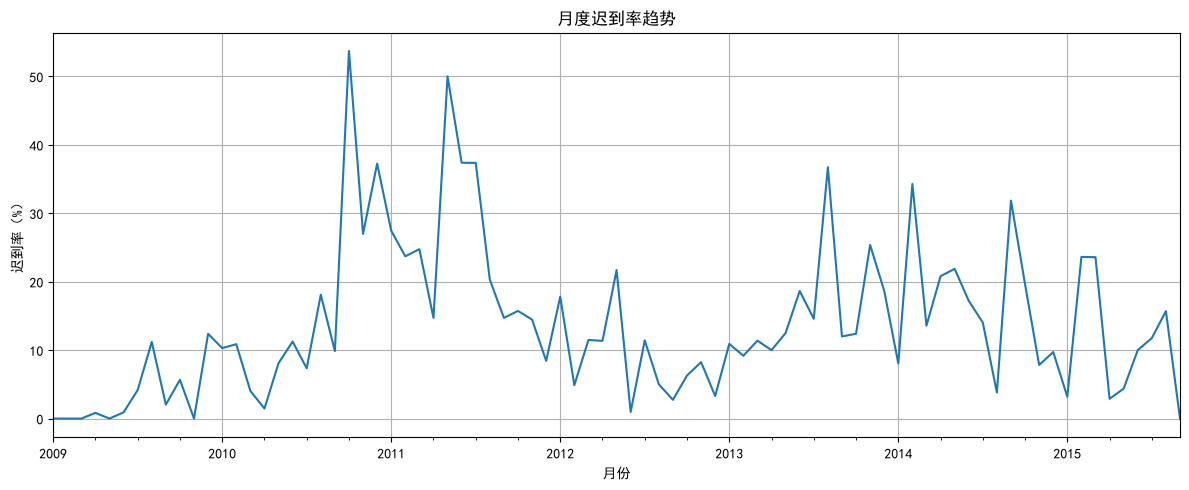

In [39]:
# 月度迟到率趋势
month_plot = month_trend.loc[pd.Period("2009-01", freq="M"):] 

month_plot["迟到率"].plot(
    figsize=(12, 5),
    title="月度迟到率趋势",
    grid=True,
)
plt.xlabel("月份")
plt.ylabel("迟到率（%）")
plt.tight_layout()
plt.savefig("charts/monthly_late_rate.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. 问题三：重量与运费是什么关系？

用双对数散点图和相关系数分析重量与运费的关系，并检查两端的异常订单。

In [40]:
import matplotlib.pyplot as plt

df_valid = df[["weight_kg", "freight_usd"]].dropna()
print(f"有效样本量：{len(df_valid)} 条")

有效样本量：6175 条


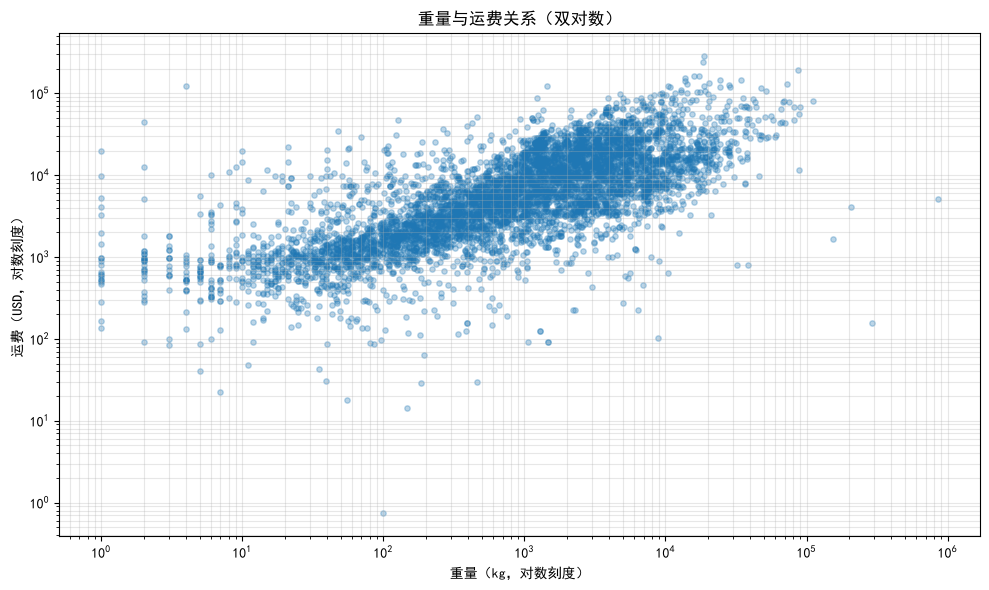

In [41]:

valid_log = df_valid[
    (df_valid["weight_kg"] > 0) & (df_valid["freight_usd"] > 0)
]

plt.figure(figsize=(10, 6))
plt.scatter(
    valid_log["weight_kg"],
    valid_log["freight_usd"],
    alpha=0.3,
    s=15,
)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("重量（kg，对数刻度）")
plt.ylabel("运费（USD，对数刻度）")
plt.title("重量与运费关系（双对数）")
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.savefig("charts/weight_freight.png", dpi=300, bbox_inches="tight")
plt.show()

In [42]:
import numpy as np

pearson = df_valid["weight_kg"].corr(df_valid["freight_usd"])
spearman = df_valid["weight_kg"].corr(df_valid["freight_usd"], method="spearman")
loglog = np.log(valid_log["weight_kg"]).corr(np.log(valid_log["freight_usd"]))

print(f"Pearson: {pearson:.3f}")
print(f"Spearman: {spearman:.3f}")
print(f"log-log Pearson: {loglog:.3f}")

Pearson: 0.232
Spearman: 0.742
log-log Pearson: 0.729


In [44]:
valid = df.dropna(subset=["weight_kg", "freight_usd"]).copy()
valid = valid.loc[valid["weight_kg"] > 0]
valid["freight_per_kg"] = valid["freight_usd"] / valid["weight_kg"]

valid["freight_per_kg"].describe(percentiles=[0.01, 0.5, 0.99])

count     6174.000000
mean        38.930123
std        581.780481
min          0.000539
1%           0.356398
50%          7.263902
99%        424.613182
max      31087.705000
Name: freight_per_kg, dtype: float64

In [45]:
cols = ["Shipment Mode", "Country", "Vendor", "weight_kg", "freight_usd", "freight_per_kg"]

valid.nlargest(10, "freight_per_kg")[cols]

,Shipment Mode,Country,Vendor,weight_kg,freight_usd,freight_per_kg
9881,Air Charter,Nigeria,SCMS from RDC,4.0,124350.82,31087.705
8801,Air Charter,Nigeria,SCMS from RDC,2.0,45180.62,22590.310
1423,Air,Nigeria,SCMS from RDC,1.0,19480.97,19480.970
1048,Unknown,Côte d'Ivoire,SCMS from RDC,1.0,9789.07,9789.070
259,Air,Kenya,"Trinity Biotech, Plc",2.0,12561.40,6280.700
10125,Truck,Uganda,SCMS from RDC,1.0,5220.79,5220.790
5393,Air,South Africa,Aurobindo Pharma Limited,1.0,4116.81,4116.810
8617,Air,Rwanda,SCMS from RDC,1.0,3253.88,3253.880
5592,Air,Guyana,"Orgenics, Ltd",2.0,5110.28,2555.140
3303,Air,Tanzania,"Trinity Biotech, Plc",1.0,1979.10,1979.100


In [46]:
valid.nsmallest(10, "freight_per_kg")[cols]

,Shipment Mode,Country,Vendor,weight_kg,freight_usd,freight_per_kg
779,Air,Côte d'Ivoire,Abbott GmbH & Co. KG,291096.0,156.97,0.000539
417,Air,Zambia,Abbott GmbH & Co. KG,857354.0,5157.65,0.006016
34,Air,Rwanda,"Orgenics, Ltd",99.0,0.75,0.007576
4922,Air,Côte d'Ivoire,Aurobindo Pharma Limited,154780.0,1664.12,0.010752
10252,Air,Zimbabwe,SCMS from RDC,8894.0,102.67,0.011544
661,Air,Côte d'Ivoire,Abbott GmbH & Co. KG,205503.0,4110.88,0.020004
536,Air,Guyana,Abbott GmbH & Co. KG,38681.0,801.54,0.020722
856,Air,Haiti,MYLAN LABORATORIES LTD (FORMERLY MATRIX LABORA...,32050.0,806.55,0.025165
7022,Truck,Zimbabwe,SCMS from RDC,6368.0,225.79,0.035457
260,Air,Kenya,"Trinity Biotech, Plc",4995.0,275.00,0.055055


In [47]:
valid.groupby("Shipment Mode")["freight_per_kg"].describe()

,count,mean,std,min,25%,50%,75%,max
Shipment Mode,,,,,,,,
Air,4096.0,33.520458,341.013073,0.000539,5.387306,10.024020,17.881496,19480.970
Air Charter,423.0,162.328929,1867.328805,0.435708,2.063230,4.317785,14.752772,31087.705
Ocean,282.0,20.662666,160.559982,0.060783,1.137491,1.681020,2.873973,1951.898
Truck,1162.0,14.440805,165.377868,0.035457,1.075661,2.503295,5.670986,5220.790
Unknown,211.0,55.841524,673.549824,0.474326,3.543030,4.654915,7.700668,9789.070


In [48]:
print("重量 <= 0:", (valid["weight_kg"] <= 0).sum())
print("运费 <= 0:", (valid["freight_usd"] <= 0).sum())
print("重量最小值:", valid["weight_kg"].min())
print("运费最小值:", valid["freight_usd"].min())

重量 <= 0: 0
运费 <= 0: 0
重量最小值: 1.0
运费最小值: 0.75


## 8. 结论与建议

### 发现 1：空运订单量最大，但海运和卡车的迟到率明显更高
空运 6,113 单，迟到率 9.6%；海运 371 单，迟到率 17.5%；卡车 2,830 单，迟到率 16.1%。海运和卡车接近，均约为空运的 1.7–1.8 倍。卡车的平均延误为 -9.9 天，但迟到率仍有 16.1%，说明它要么提前很多、要么迟到，时效分布比海运更分散。

### 发现 2：延误集中在少数供应商、国家和时段
供应商方面，SCMS from RDC 占全部订单的 52%（5,404/10,324），贡献了 78% 的迟到订单（927/1,186），迟到率 17.2%，高于整体 11.5%。国家方面，Burundi（38.8%，98 单）、Congo, DRC（24.9%，333 单）、Mozambique（18.4%，631 单）的迟到率明显偏高；但 Burundi 样本不足 100 单，结论要谨慎。月份方面，2010-10（53.7%，54 单）、2011-05（50.0%，74 单）、2011-06（37.4%，107 单）迟到率偏高，但这些月份样本量不大，更适合看作阶段性波动，而不是稳定规律。

### 发现 3：重量与运费整体正相关，但关系是非线性的，并存在明显异常订单
在 6,174 条有效记录中，Pearson 只有 0.232，但 Spearman 为 0.742，取对数后 Pearson 为 0.729——说明重量越大运费越高，但不是线性增长；只看 Pearson 会低估关系。分运输方式看，空运的线性相关最弱（0.112），但 Spearman 高达 0.807，说明空运内部更接近非线性关系；卡车和空运包机的线性相关更强（0.607、0.637）。按单位重量运费中位数，空运 10.02、空运包机 4.32、卡车 2.50、海运 1.68 USD/kg，空运约为海运的 6 倍。异常订单集中在两端：一端是 1–4 kg 却运费上万美元的极小额急件（最高 31,088 USD/kg），另一端是几十万公斤却运费极低的记录（最低 0.0005 USD/kg），后者更像重量或运费录入错误，建议核查。

### 建议
1. **对海运和卡车增加计划缓冲期，优先复盘高风险组合。** 重点跟踪 SCMS from RDC、Burundi、Congo DRC、Mozambique 的迟到订单，分析是路线、清关还是排期问题。
2. **建立重量和运费的数据校验规则。** 对单位重量运费超过 P99、重量或运费为 0 或极端值的记录自动标记，避免异常值影响成本分析。

### 局限
- 国家和供应商分析只保留订单量 ≥50 的组，避免小样本导致的迟到率波动，但会漏掉小供应商的异常。
- 重量和运费同时有效的记录只有 6,174/10,324（59.8%）；卡车只有 41% 的记录两者齐全，分运输方式的成本结论对卡车要谨慎。
- 异常值保留在相关性计算中，未删除；只在解释时单独讨论。
- 数据截至 2015 年，不能代表当前运营状况；相关不等于因果，迟到率还受路线、天气、清关等未观测因素影响。